In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

mpg = sns.load_dataset("mpg")

mpg.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [2]:
mpg.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [3]:
mpg.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

# Bloque I: Análisis de Tendencias


## Pregunta 1: ¿Cómo ha evolucionado el rendimiento promedio de combustible a lo largo de los años del modelo?


In [4]:
promedio_anual = mpg.groupby("model_year")["mpg"].mean()

promedio_anual

model_year
70    17.689655
71    21.250000
72    18.714286
73    17.100000
74    22.703704
75    20.266667
76    21.573529
77    23.375000
78    24.061111
79    25.093103
80    33.696552
81    30.334483
82    31.709677
Name: mpg, dtype: float64

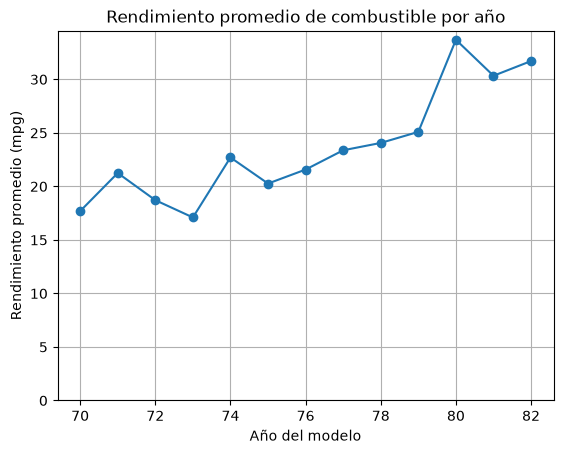

In [5]:
promedio_anual.plot(kind="line", marker="o")

plt.title("Rendimiento promedio de combustible por año")
plt.xlabel("Año del modelo")
plt.ylabel("Rendimiento promedio (mpg)")
plt.ylim(bottom=0)
plt.grid()

plt.show()

In [6]:
primer_anio = promedio_anual.iloc[0]
ultimo_anio = promedio_anual.iloc[-1]

cambio_mpg = ultimo_anio - primer_anio
cambio_porcentaje = (cambio_mpg / primer_anio) * 100

print("Primer año:", primer_anio)
print("Último año:", ultimo_anio)
print("Cambio en mpg:", cambio_mpg)
print("Cambio porcentual:", cambio_porcentaje)

Primer año: 17.689655172413794
Último año: 31.70967741935484
Cambio en mpg: 14.020022246941046
Cambio porcentual: 79.25548638621643


**Respuestas**
1. ¿La tendencia es creciente, decreciente o estable?
Es creciente. Conforme avanzan los años del modelo, aumenta en general el rendimiento promedio de combustible.
2. ¿Existe algún año donde se rompe el patrón?
Sí. Aunque la tendencia general es creciente, existen algunos años donde el promedio disminuye respecto al año anterior. Por ejemplo, se pueden observar pequeñas caídas alrededor de 1972-1973, 1975 y 1981.
3. ¿Qué magnitud tiene el cambio entre el primer y último año?
El rendimiento pasa aproximadamente de 17.69 mpg a 31.71 mpg, un incremento de aproximadamente 14.02 mpg, equivalente a cerca del 79 %.
4. ¿Qué factores ingenieriles podrían explicar esta tendencia?
Podrían influir motores más eficientes, reducción del peso de los vehículos, mejoras en combustión, aerodinámica, sistemas de transmisión más eficientes y cambios tecnológicos orientados a reducir el consumo de combustible.

**Interpretación técnica**

El rendimiento promedio de combustible presenta una tendencia general creciente a través de los años del modelo. Los vehículos más recientes del dataset alcanzan valores de mpg considerablemente superiores a los vehículos de los primeros años. Aunque existen algunas fluctuaciones entre años consecutivos, el patrón global muestra una mejora en la eficiencia energética. Entre el primer y último año se observa un incremento cercano al 79 %. Esto podría relacionarse con avances tecnológicos en motores, reducción del peso de los vehículos y diseños orientados a mejorar el consumo de combustible.

## Pregunta 2: ¿Cómo se distribuye la potencia (horsepower) de los vehículos y existen valores atípicos?


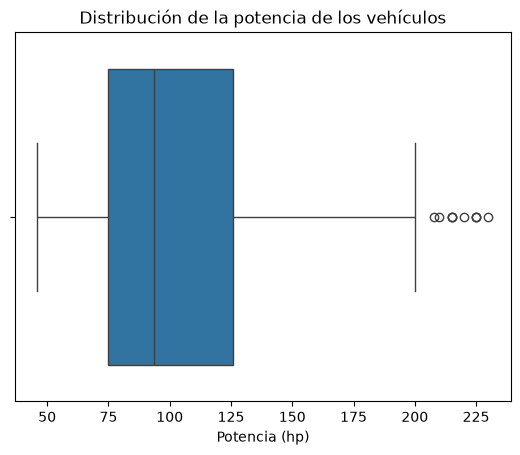

In [7]:
sns.boxplot(x=mpg["horsepower"])

plt.title("Distribución de la potencia de los vehículos")
plt.xlabel("Potencia (hp)")

plt.show()

In [8]:
hp = mpg["horsepower"].dropna()

Q1 = hp.quantile(0.25)
Q3 = hp.quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

atipicos = hp[(hp < limite_inferior) | (hp > limite_superior)]

print("Media:", hp.mean())
print("Mediana:", hp.median())
print("Q1:", Q1)
print("Q3:", Q3)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Cantidad de valores atípicos:", len(atipicos))

print("\nValores atípicos:")
print(atipicos)

Media: 104.46938775510205
Mediana: 93.5
Q1: 75.0
Q3: 126.0
Límite inferior: -1.5
Límite superior: 202.5
Cantidad de valores atípicos: 10

Valores atípicos:
6      220.0
7      215.0
8      225.0
13     225.0
25     215.0
27     210.0
67     208.0
94     215.0
95     225.0
116    230.0
Name: horsepower, dtype: float64


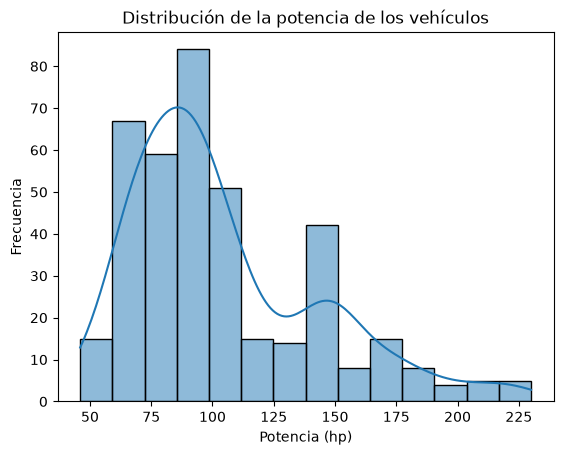

In [9]:
sns.histplot(data=mpg, x="horsepower", kde=True)

plt.title("Distribución de la potencia de los vehículos")
plt.xlabel("Potencia (hp)")
plt.ylabel("Frecuencia")

plt.show()

**Respuestas**
1. ¿La distribución es simétrica, sesgada a la derecha o izquierda?
La distribución presenta sesgo hacia la derecha, ya que existen algunos vehículos con potencias considerablemente mayores al resto.
2. ¿Qué representan los valores atípicos?
Representan vehículos con motores de potencia considerablemente superior a la mayoría de vehículos del dataset.
3. ¿Qué indica la posición de la mediana respecto a la media?
La media es mayor que la mediana. Esto es consistente con una distribución sesgada hacia la derecha, ya que los valores altos de potencia elevan la media.
4. ¿Sería apropiado usar la media como medida representativa?
La media puede utilizarse, pero la mediana es más robusta porque no se ve tan afectada por los valores extremos.

**Interpretación técnica**

La distribución de horsepower presenta un sesgo positivo o hacia la derecha. La mayoría de los vehículos se concentran en valores de potencia relativamente bajos y medios, mientras que existe un grupo reducido de vehículos con potencias considerablemente mayores. Estos vehículos aparecen como valores atípicos en el boxplot. Debido a esta asimetría, la mediana puede representar mejor la potencia típica de los vehículos que la media.

## Pregunta 3: ¿Cómo se relacionan el peso del vehículo y el rendimiento de combustible?


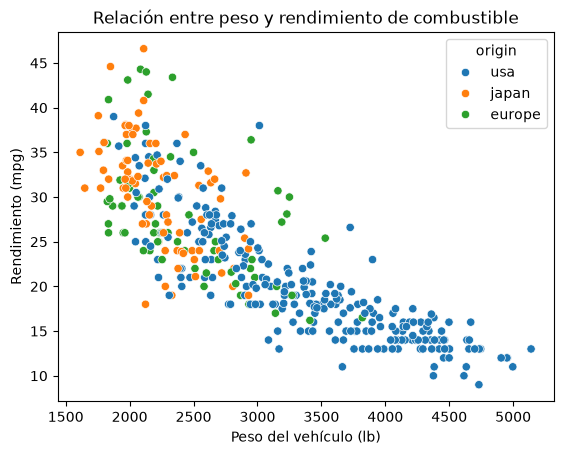

In [10]:
sns.scatterplot(
    data=mpg,
    x="weight",
    y="mpg",
    hue="origin"
)

plt.title("Relación entre peso y rendimiento de combustible")
plt.xlabel("Peso del vehículo (lb)")
plt.ylabel("Rendimiento (mpg)")

plt.show()

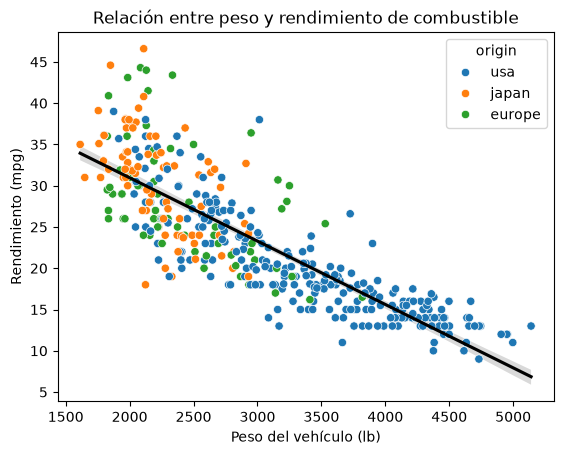

In [11]:
sns.regplot(
    data=mpg,
    x="weight",
    y="mpg",
    scatter=False,
    color="black"
)

sns.scatterplot(
    data=mpg,
    x="weight",
    y="mpg",
    hue="origin"
)

plt.title("Relación entre peso y rendimiento de combustible")
plt.xlabel("Peso del vehículo (lb)")
plt.ylabel("Rendimiento (mpg)")

plt.show()

In [12]:
correlacion = mpg["weight"].corr(mpg["mpg"])

print("Correlación de Pearson:", correlacion)

Correlación de Pearson: -0.8317409332443354


**Respuestas**
1. ¿La relación es positiva o negativa?
Es negativa. Conforme aumenta el peso del vehículo, el rendimiento en mpg tiende a disminuir.
Físicamente esto significa que un vehículo más pesado generalmente requiere más energía y combustible para desplazarse.
2. ¿La relación parece lineal?
Existe una relación aproximadamente lineal negativa bastante marcada, aunque se observan ciertas variaciones y una posible ligera curvatura.
3. ¿Los vehículos de distintos orígenes se comportan igual?
Los tres orígenes muestran una tendencia general similar: mayor peso implica menor rendimiento. Sin embargo, existen diferencias en las zonas donde se concentran los vehículos de cada origen.
4. Coeficiente de correlación
Aproximadamente:
r ≈ -0.83
Esto representa una correlación negativa fuerte.
5. ¿Qué implicaciones tiene esto para el diseño?
La reducción del peso puede ser una estrategia importante para aumentar la eficiencia energética y disminuir el consumo de combustible.

**Interpretación técnica**

El peso del vehículo y el rendimiento de combustible presentan una fuerte relación negativa. El coeficiente de correlación de Pearson es aproximadamente -0.83, indicando que los vehículos más pesados tienden a presentar menores valores de mpg. Este comportamiento aparece en los diferentes países de origen, aunque la distribución de pesos varía entre grupos. Desde el punto de vista ingenieril, reducir la masa del vehículo puede contribuir a mejorar la eficiencia energética.

**No hay pregunta 4 inge :(**

## Bloque II: Análisis Comparativo


## Pregunta 5: ¿Existen diferencias en el rendimiento (mpg) según el número de cilindros?


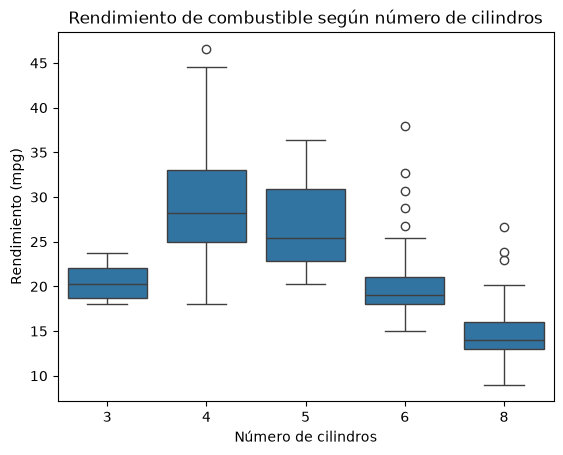

In [13]:
sns.boxplot(
    data=mpg,
    x="cylinders",
    y="mpg"
)

plt.title("Rendimiento de combustible según número de cilindros")
plt.xlabel("Número de cilindros")
plt.ylabel("Rendimiento (mpg)")

plt.show()

In [14]:
print(
    mpg.groupby("cylinders")["mpg"]
       .median()
)

cylinders
3    20.25
4    28.25
5    25.40
6    19.00
8    14.00
Name: mpg, dtype: float64


In [15]:
print(
    mpg.groupby("cylinders")["mpg"]
       .std()
)

cylinders
3    2.564501
4    5.710156
5    8.228204
6    3.807322
8    2.836284
Name: mpg, dtype: float64


**Respuestas**
1. ¿Cómo varía la mediana al aumentar los cilindros?
En general, la mediana de mpg disminuye conforme aumenta el número de cilindros.
2. ¿Qué grupo presenta mayor dispersión?
El grupo de 5 cilindros presenta la mayor dispersión, con una desviación estándar aproximada de 8.23 mpg. Sin embargo, este grupo tiene pocos vehículos, por lo que debe interpretarse con cautela.
3. ¿Hay solapamiento entre las cajas?
Existe cierto solapamiento entre algunos grupos cercanos, lo que significa que el número de cilindros no explica por sí solo todo el rendimiento del vehículo.
4. Hipótesis
H₀: el rendimiento promedio de combustible es igual entre los distintos números de cilindros.
H₁: al menos un grupo de cilindros presenta un rendimiento diferente.

**Interpretación técnica**

Se observa una relación clara entre el número de cilindros y el rendimiento de combustible. Los vehículos con menor número de cilindros generalmente presentan valores de mpg mayores, mientras que los vehículos con 8 cilindros presentan los menores rendimientos. Sin embargo, existe cierto solapamiento entre algunos grupos, indicando que otras características del vehículo también influyen sobre el consumo.

## Pregunta 6: ¿Existen diferencias significativas en el rendimiento según el país de origen (origin)?


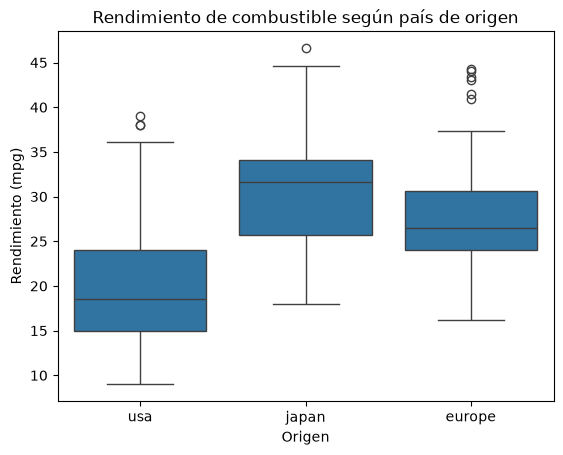

In [16]:
sns.boxplot(
    data=mpg,
    x="origin",
    y="mpg"
)

plt.title("Rendimiento de combustible según país de origen")
plt.xlabel("Origen")
plt.ylabel("Rendimiento (mpg)")

plt.show()

In [17]:
promedio_origen = mpg.groupby("origin")["mpg"].mean()

print(promedio_origen)

origin
europe    27.891429
japan     30.450633
usa       20.083534
Name: mpg, dtype: float64


In [18]:
varianza_origen = mpg.groupby("origin")["mpg"].var()

print(varianza_origen)

origin
europe    45.211230
japan     37.088685
usa       40.997026
Name: mpg, dtype: float64


**Respuestas**
1. ¿Qué origen tiene mejor rendimiento promedio? ¿Y peor?
Los vehículos de Japón presentan el mayor rendimiento promedio.
Los vehículos de Estados Unidos presentan el menor.
2. ¿La forma de las distribuciones es similar?
Las distribuciones muestran diferencias tanto en posición como en dispersión, aunque existe cierto solapamiento entre los grupos.
3. ¿Los datos sugieren igualdad de varianzas?
Las dispersiones no son exactamente iguales, por lo que no se debería asumir automáticamente igualdad de varianzas sin una prueba estadística.
4. ¿Qué variables pueden confundir la comparación?
Principalmente:
- peso,
- número de cilindros,
- potencia,
- cilindrada,
- año del vehículo.

**Interpretación técnica**

El rendimiento de combustible presenta diferencias según el origen del vehículo. Los vehículos japoneses muestran el mayor mpg promedio, seguidos por los europeos, mientras que los estadounidenses presentan el menor rendimiento promedio. Sin embargo, estas diferencias no necesariamente son causadas únicamente por el país de origen, ya que variables como peso, cilindrada, número de cilindros, potencia y año del modelo pueden actuar como factores de confusión.

## Pregunta 7: ¿Cómo interactúan el origen y el número de cilindros sobre el rendimiento?


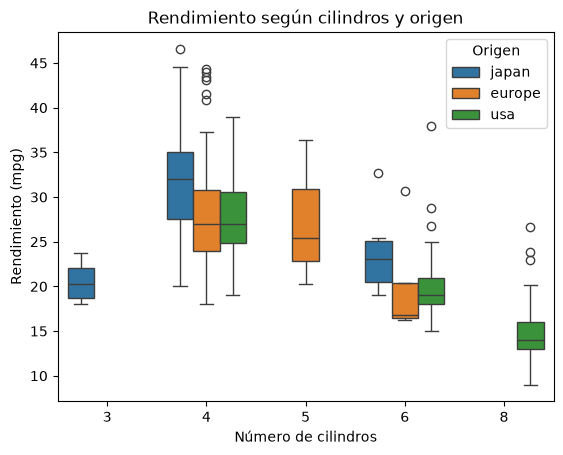

In [19]:
sns.boxplot(
    data=mpg,
    x="cylinders",
    y="mpg",
    hue="origin"
)

plt.title("Rendimiento según cilindros y origen")
plt.xlabel("Número de cilindros")
plt.ylabel("Rendimiento (mpg)")
plt.legend(title="Origen")

plt.show()

**Respuestas**
  
1. ¿El efecto de los cilindros sobre mpg es constante entre orígenes?
La tendencia general aparece en todos los orígenes: al aumentar los cilindros, disminuye el mpg. Sin embargo, la magnitud del efecto puede variar entre los grupos.
2. ¿Algún origen tiene comportamiento diferenciado?
Los vehículos japoneses y europeos suelen concentrarse en categorías de menor cantidad de cilindros y mayor rendimiento, mientras que los estadounidenses tienen mayor presencia en vehículos de 6 y 8 cilindros.
3. ¿Qué ventaja tiene este gráfico respecto a los anteriores?
Permite estudiar simultáneamente tres variables:
- rendimiento,
- cilindros,
- origen.

Esto permite determinar si las diferencias observadas en mpg pueden relacionarse tanto con el origen como con la configuración del motor.

**Interpretación técnica**

El rendimiento de combustible disminuye en general al aumentar el número de cilindros, aunque este comportamiento varía según el origen. Los vehículos japoneses y europeos se concentran principalmente en configuraciones de pocos cilindros y valores mayores de mpg, mientras que los estadounidenses presentan una mayor presencia de motores de 6 y 8 cilindros. El gráfico permite observar simultáneamente el efecto del número de cilindros y del origen, mostrando que ambas variables están relacionadas con el rendimiento de combustible.

## Pregunta 8: ¿Cómo ha cambiado la composición de cilindros y orígenes por año?


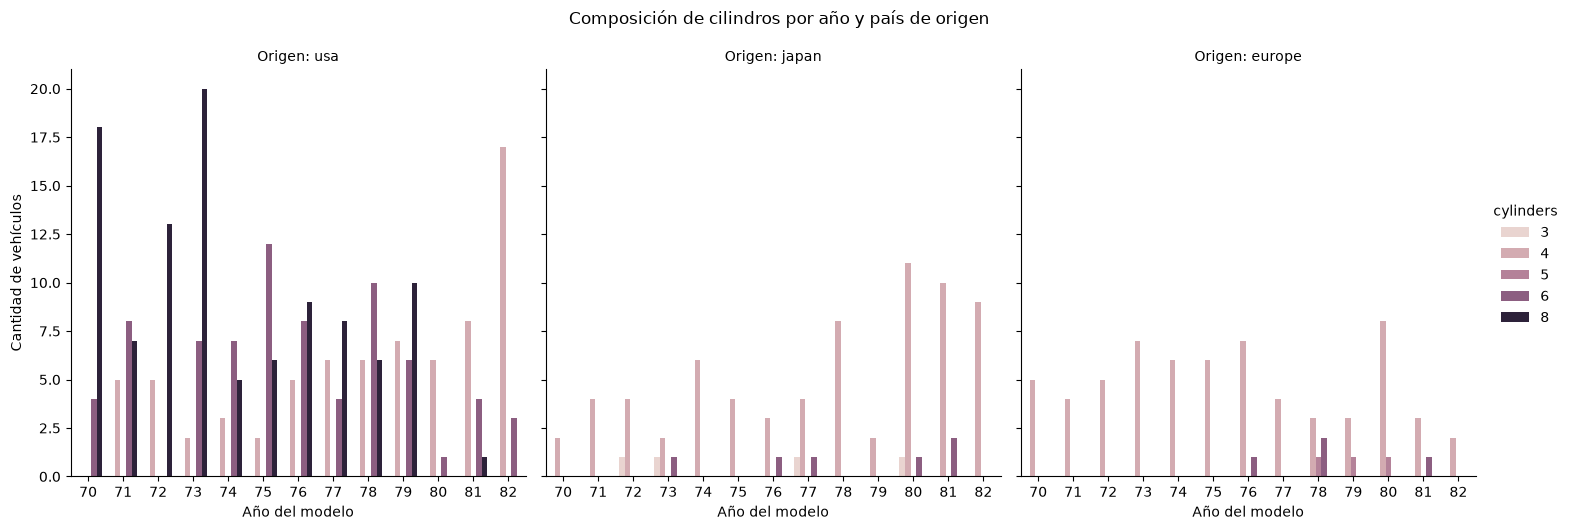

In [20]:
g = sns.catplot(
    data=mpg,
    x="model_year",
    hue="cylinders",
    col="origin",
    kind="count",
    height=5,
    aspect=1
)

g.set_axis_labels("Año del modelo", "Cantidad de vehículos")
g.set_titles("Origen: {col_name}")

g.figure.suptitle(
    "Composición de cilindros por año y país de origen",
    y=1.05
)

plt.show()

**Respuestas**

1. ¿Cómo ha evolucionado la participación de cada origen por año?
A lo largo de los años se observa una mayor diversidad en los vehículos europeos y japoneses dentro del dataset, mientras que los vehículos estadounidenses tienen una presencia importante durante todo el período.
2. ¿Disminuyó la presencia de vehículos de 8 cilindros?
Sí. Los vehículos de 8 cilindros son más frecuentes durante los primeros años, pero su presencia disminuye en los años posteriores.
3. ¿Qué relación tiene con el aumento del mpg del Bloque I?
Existe una relación coherente: mientras disminuye la presencia de vehículos grandes y de 8 cilindros y aumenta la presencia de vehículos de menor número de cilindros, también aumenta el rendimiento promedio en mpg.

**Interpretación técnica**

La composición del conjunto de vehículos cambia a través del tiempo. Durante los primeros años existe una presencia importante de vehículos de 8 cilindros, particularmente estadounidenses. En los años posteriores aumenta la participación de vehículos con motores de menor número de cilindros. Este cambio coincide con el incremento del mpg promedio observado en el Bloque I, lo que sugiere que parte de la mejora en eficiencia puede estar relacionada con una transición hacia vehículos más pequeños, ligeros y con motores de menor cilindrada.

# Bloque III: Diseño de su Propio Análisis


## Pregunta de análisis propuesta

**¿Cómo se relaciona la potencia del motor con la aceleración de los vehículos según su país de origen?**

**Variables involucradas:**

- **Eje X:** horsepower
- **Eje Y:** acceleration
- **Color/grupo:** origin

**Tipo de gráfico seleccionado:** Gráfico de dispersión (scatterplot).

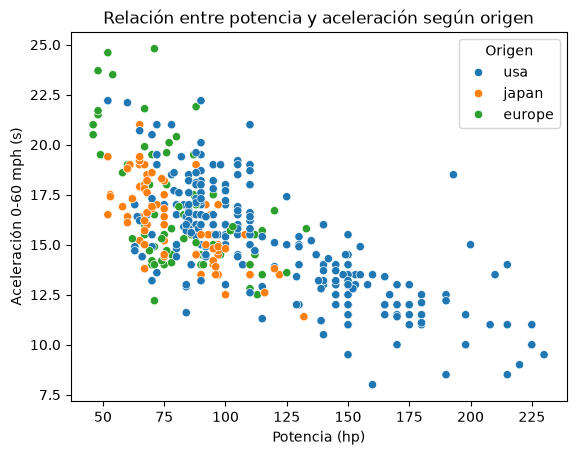

In [21]:
sns.scatterplot(
    data=mpg,
    x="horsepower",
    y="acceleration",
    hue="origin"
)

plt.title("Relación entre potencia y aceleración según origen")
plt.xlabel("Potencia (hp)")
plt.ylabel("Aceleración 0-60 mph (s)")
plt.legend(title="Origen")

plt.show()

In [22]:
correlacion = mpg["horsepower"].corr(mpg["acceleration"])

print("Correlación:", correlacion)

Correlación: -0.6891955103342361


**Justificación del gráfico**

Se seleccionó un gráfico de dispersión porque las variables horsepower y acceleration son cuantitativas. Este tipo de gráfico permite visualizar la dirección, intensidad y forma de la relación entre ambas variables. Además, el uso del color según origin permite comparar si la relación presenta diferencias entre vehículos estadounidenses, europeos y japoneses.

**Interpretación técnica**

El gráfico permite observar la relación entre la potencia del motor y el tiempo de aceleración de los vehículos. En general, los automóviles con mayor potencia presentan tiempos de aceleración diferentes a los vehículos de menor potencia. La distribución de los puntos permite identificar si existe una asociación entre ambas variables y determinar su dirección. También se observan diferencias en las zonas donde se concentran los vehículos según su país de origen. Los vehículos estadounidenses presentan una mayor presencia en niveles elevados de potencia, mientras que los japoneses y europeos se concentran principalmente en valores menores. Sin embargo, existe solapamiento entre los diferentes grupos. Esto demuestra que la aceleración no depende únicamente de la potencia, sino también de otras características como el peso, la transmisión y las características del motor.

### Matriz de Autoevaluación de sus Gráficos

| Criterio | ✓ | X | Comentario |
|---|:---:|:---:|---|
| El título describe qué se muestra (no solo "Gráfico de mpg") | ✓ |  | Cada gráfico presenta un título específico relacionado con el análisis realizado. |
| Los ejes tienen etiquetas con unidades | ✓ |  | Se indican las variables y unidades como mpg, hp, lb y segundos cuando corresponde. |
| La escala del eje Y comienza en cero (cuando aplica) | ✓ |  | Se utiliza escala desde cero cuando corresponde; en boxplots y scatterplots no siempre es necesario. |
| El uso del color es informativo, no decorativo | ✓ |  | Los colores distinguen variables categóricas como origen y número de cilindros. |
| Se incluye leyenda cuando hay múltiples grupos | ✓ |  | Las gráficas con varios grupos incluyen una leyenda para identificarlos. |
| No hay "chartjunk" (elementos innecesarios) | ✓ |  | Se evitaron elementos visuales innecesarios para mantener las gráficas claras. |
| El tipo de gráfico corresponde a la naturaleza de las variables | ✓ |  | Se utilizaron líneas, boxplots y diagramas de dispersión según el tipo de análisis. |